# Exploratory analysis: next-month transactional inactivity

**Target:** `InactiveNextMonth` = active in month T and zero transactions in T+1.
This is a *transactional inactivity proxy*, not confirmed account closure.
All comparisons are descriptive associations on labelled customer-month rows (T = Jun-Nov 2023);
they do not imply causation. Customer-profile cuts use the undated `DimCustomer` snapshot for
segmentation only, never as model input.

In [1]:

import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import duckdb, numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200, "display.max_columns", 30)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").exists())
P = ROOT / "data" / "processed"
db = duckdb.connect()
db.execute(f"CREATE VIEW cf AS SELECT * FROM read_parquet('{(P / 'churn_features.parquet').as_posix()}')")
db.execute(f"CREATE VIEW dim AS SELECT * FROM read_parquet('{(P / 'dim_customer.parquet').as_posix()}')")
lab = db.execute("""SELECT f.*, strftime(Month,'%Y-%m') AS period FROM cf f WHERE EligibleForTraining = 1""").fetchdf()
lab["y"] = lab["InactiveNextMonth"].astype(int)
print(f"{len(lab):,} labelled customer-month rows; {lab.customer_id.nunique():,} customers; positive rate {lab.y.mean():.2%}")


224,360 labelled customer-month rows; 48,674 customers; positive rate 17.40%


## 1. Target distribution (overall and by month)

,rows,inactive_next_month=1,rate %
overall,224360.0,39039.0,17.4


,rows,inactive,rate
period,,,
2023-06,31362,4649,14.82
2023-07,37114,6196,16.69
2023-08,38795,6971,17.97
2023-09,38822,6698,17.25
2023-10,39389,7193,18.26
2023-11,38878,7332,18.86


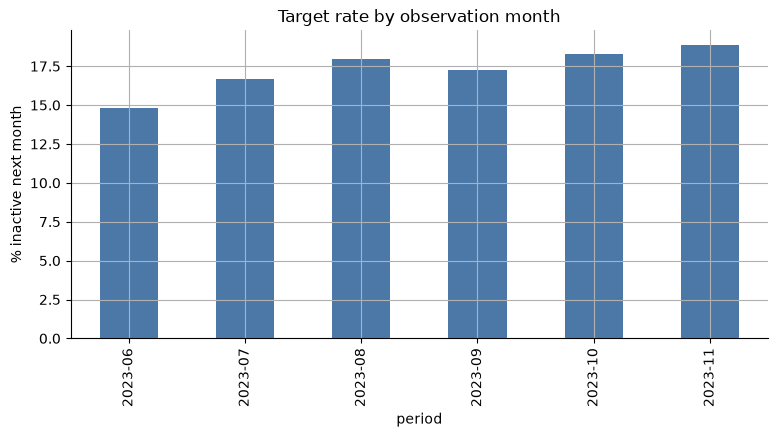

Range across months: 14.82% - 18.86%


In [2]:

by_month = lab.groupby("period").y.agg(rows="size", inactive="sum", rate="mean")
by_month["rate"] = (by_month["rate"] * 100).round(2)
display(pd.DataFrame({"overall": [len(lab), int(lab.y.sum()), round(lab.y.mean() * 100, 2)]}, index=["rows", "inactive_next_month=1", "rate %"]).T)
display(by_month)
ax = by_month["rate"].plot(kind="bar", color="#4C78A8"); ax.set_ylabel("% inactive next month"); ax.set_title("Target rate by observation month"); plt.show()
print("Range across months: %.2f%% - %.2f%%" % (by_month.rate.min(), by_month.rate.max()))


### Are inactive-next-month customers really gone? (transient gaps)

In [3]:

gap = db.execute("""
WITH t AS (SELECT customer_id, Month, TransactionCount tc, InactiveNextMonth y,
           lead(TransactionCount,2) OVER (PARTITION BY customer_id ORDER BY Month) n2,
           ExtendedInactivityNext3Months e FROM cf)
SELECT COUNT(*) FILTER (WHERE y=1) AS inactive_next_month,
       COUNT(*) FILTER (WHERE y=1 AND n2>0) AS active_again_at_T_plus_2,
       ROUND(100.0*COUNT(*) FILTER (WHERE y=1 AND n2>0)/NULLIF(COUNT(*) FILTER (WHERE y=1 AND n2 IS NOT NULL),0),1) AS pct_return_T_plus_2,
       COUNT(*) FILTER (WHERE e=1) AS extended_inactivity_3m, COUNT(*) FILTER (WHERE e IS NOT NULL) AS extended_observed
FROM t""").fetchdf()
display(gap)


,inactive_next_month,active_again_at_T_plus_2,pct_return_T_plus_2,extended_inactivity_3m,extended_observed
0,76868,50512,72.6,4723,350870


## 2. Behavioural deterioration: inactive-next-month vs active-next-month

,median_active_next,median_inactive_next,mean_active_next,mean_inactive_next,std_diff,null_rate_%
feature,,,,,,
TransactionCount,2.000,2.000,8.177000e+00,1.847,-0.137,0.00
TotalAmount,5516850.000,3083350.000,3.417088e+07,6812945.950,-0.055,0.00
ActiveDays,2.000,2.000,4.194000e+00,1.805,-0.651,0.00
DaysSinceLastTransaction,6.000,10.000,8.521000e+00,11.365,0.345,0.00
TransactionCountChangePct,0.000,0.000,2.560000e-01,0.259,0.003,17.04
TotalAmountChangePct,-0.009,-0.000,6.900000e-01,0.857,0.061,17.04
TransactionCount_3M_ChangePct,0.000,0.000,2.830000e-01,0.466,0.167,1.08
TotalAmount_3M_ChangePct,0.083,0.135,5.630000e-01,0.926,0.142,1.08


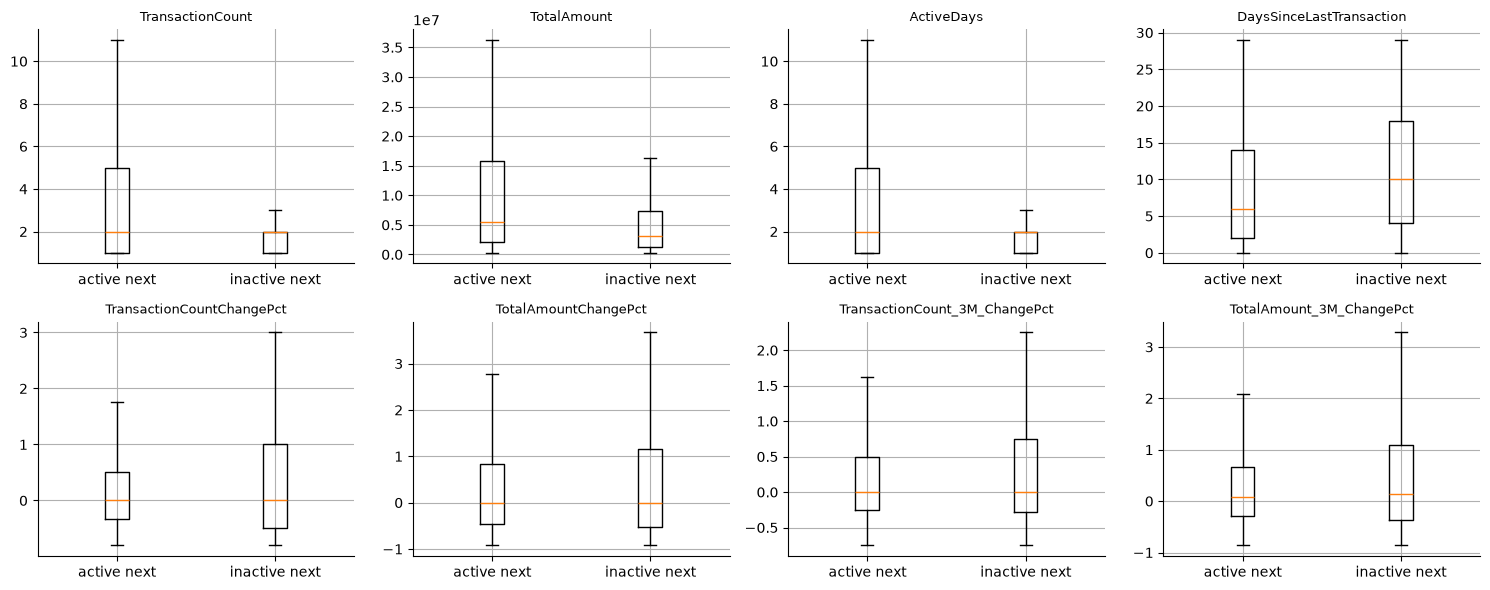

In [4]:

cols = ["TransactionCount", "TotalAmount", "ActiveDays", "DaysSinceLastTransaction",
        "TransactionCountChangePct", "TotalAmountChangePct",
        "TransactionCount_3M_ChangePct", "TotalAmount_3M_ChangePct"]
rows = []
for c in cols:
    a, b = lab.loc[lab.y == 0, c].astype(float), lab.loc[lab.y == 1, c].astype(float)
    pooled = np.sqrt((a.var() + b.var()) / 2)
    rows.append({"feature": c, "median_active_next": a.median(), "median_inactive_next": b.median(),
                 "mean_active_next": a.mean(), "mean_inactive_next": b.mean(),
                 "std_diff": (b.mean() - a.mean()) / pooled if pooled else np.nan,
                 "null_rate_%": round(lab[c].isna().mean() * 100, 2)})
cmp = pd.DataFrame(rows).set_index("feature")
display(cmp.round(3))
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, c in zip(axes.ravel(), cols):
    data = [lab.loc[lab.y == v, c].dropna().clip(lab[c].quantile(.01), lab[c].quantile(.99)) for v in (0, 1)]
    ax.boxplot(data, tick_labels=["active next", "inactive next"], showfliers=False); ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()


### Monthly trend before the event: average TransactionCount by months-to-inactivity

grp,active next month,inactive next month
rel_month,,
-5,7.72,1.41
-4,7.79,1.36
-3,7.93,1.37
-2,7.89,1.37
-1,7.94,1.37
0,8.18,1.85


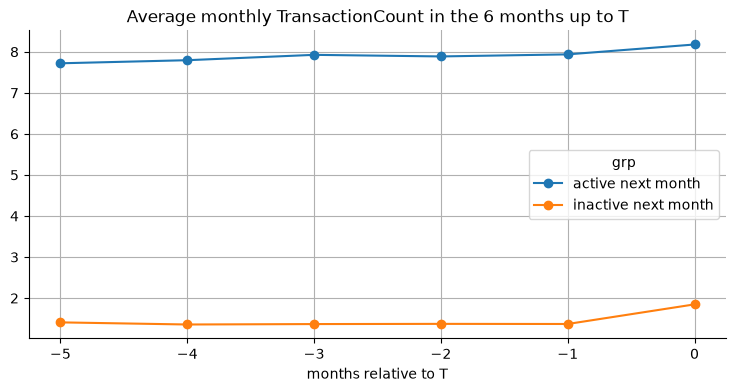

In [5]:

trend = db.execute("""
WITH ev AS (SELECT customer_id, Month AS event_month FROM cf WHERE EligibleForTraining=1 AND InactiveNextMonth=1),
base AS (SELECT customer_id, Month AS event_month FROM cf WHERE EligibleForTraining=1 AND InactiveNextMonth=0)
SELECT 'inactive next month' AS grp, date_diff('month', e.event_month, f.Month) AS rel_month, AVG(f.TransactionCount) AS avg_tx
FROM ev e JOIN cf f ON f.customer_id=e.customer_id AND date_diff('month', e.event_month, f.Month) BETWEEN -5 AND 0 GROUP BY 1,2
UNION ALL
SELECT 'active next month', date_diff('month', e.event_month, f.Month), AVG(f.TransactionCount)
FROM base e JOIN cf f ON f.customer_id=e.customer_id AND date_diff('month', e.event_month, f.Month) BETWEEN -5 AND 0 GROUP BY 1,2
""").fetchdf().pivot(index="rel_month", columns="grp", values="avg_tx")
display(trend.round(2)); trend.plot(marker="o", title="Average monthly TransactionCount in the 6 months up to T"); plt.xlabel("months relative to T"); plt.show()


## 3. Transaction composition

,active next,inactive next,diff (pp)
PaymentShare,0.3063,0.3092,0.29
TransferShare,0.4507,0.4494,-0.13
WithdrawalShare,0.1468,0.1431,-0.37
DepositShare,0.0962,0.0984,0.22


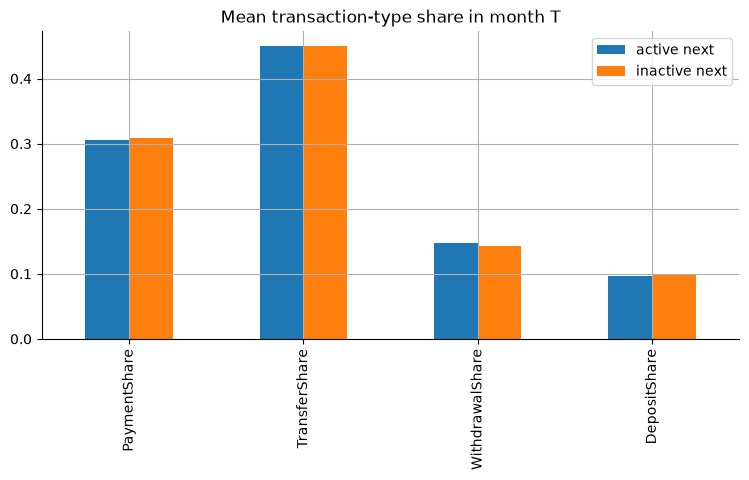

,rows,rate
PreferredTransactionType,,
Deposit,9573,23.26
Payment,58164,18.59
Transfer,138466,16.05
Withdrawal,18157,20.81


In [6]:

shares = ["PaymentShare", "TransferShare", "WithdrawalShare", "DepositShare"]
comp = lab.groupby("y")[shares].mean().T; comp.columns = ["active next", "inactive next"]
comp["diff (pp)"] = ((comp["inactive next"] - comp["active next"]) * 100).round(2)
display((comp * [100, 100, 1]).round(2) if False else comp.round(4))
comp[["active next", "inactive next"]].plot(kind="bar", title="Mean transaction-type share in month T"); plt.show()
pref = lab.groupby("PreferredTransactionType").y.agg(rows="size", rate="mean"); pref["rate"] = (pref.rate * 100).round(2); display(pref)


## 4. Recency: DaysSinceLastTransaction vs next-month inactivity

,rows,rate_%
recency_bin,,
"(-1, 0]",27759,8.22
"(0, 3]",49742,12.84
"(3, 7]",42701,16.62
"(7, 14]",48484,20.45
"(14, 21]",30870,23.30
"(21, 31]",24804,24.85


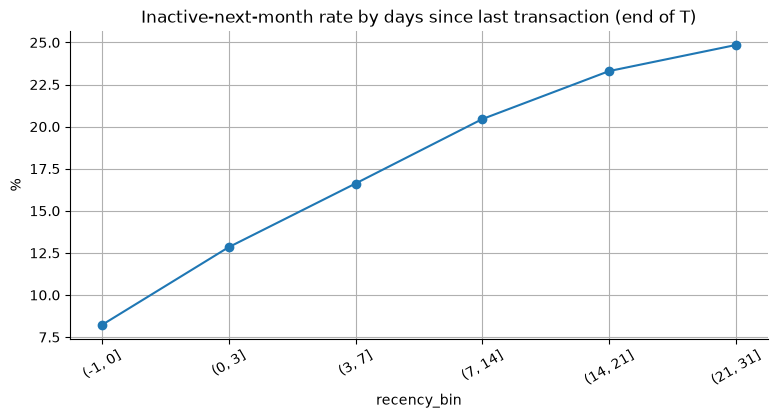

In [7]:

bins = [-1, 0, 3, 7, 14, 21, 31, 60, 400]
lab["recency_bin"] = pd.cut(lab.DaysSinceLastTransaction, bins=bins)
rec = lab.groupby("recency_bin", observed=True).y.agg(rows="size", rate="mean"); rec["rate_%"] = (rec.pop("rate") * 100).round(2)
display(rec)
ax = rec["rate_%"].plot(marker="o", title="Inactive-next-month rate by days since last transaction (end of T)")
ax.set_xticks(range(len(rec))); ax.set_xticklabels([str(i) for i in rec.index], rotation=30); ax.set_ylabel("%"); plt.show()


## 5. Customer characteristics (segmentation only, no causal claim)

In [8]:

seg = lab.merge(db.execute("SELECT customer_id, age, gender, location, income_bracket, acquisition_channel, education_level, occupation FROM dim").fetchdf(), on="customer_id", how="left")
overall = seg.y.mean()
for col in ["age", "income_bracket", "acquisition_channel", "education_level", "gender", "location", "occupation"]:
    t = seg.groupby(col).agg(rows=("y", "size"), customers=("customer_id", "nunique"), rate=("y", "mean"))
    t = t[t.rows >= 500]; t["rate_%"] = (t.pop("rate") * 100).round(2); t["vs_overall_pp"] = (t["rate_%"] - overall * 100).round(2)
    print(f"--- {col}  (overall {overall:.2%}; groups with >=500 customer-months; spread {t['rate_%'].max() - t['rate_%'].min():.2f} pp)")
    display(t.sort_values("rate_%", ascending=False).head(12))


--- age  (overall 17.40%; groups with >=500 customer-months; spread 0.66 pp)


,rows,customers,rate_%,vs_overall_pp
age,,,,
30,37180,8097,17.71,0.31
45,37157,8078,17.70,0.30
60,37635,8168,17.47,0.07
59,37775,8179,17.39,-0.01
29,37491,8103,17.09,-0.31
44,37122,8049,17.05,-0.35


--- income_bracket  (overall 17.40%; groups with >=500 customer-months; spread 0.17 pp)


,rows,customers,rate_%,vs_overall_pp
income_bracket,,,,
Medium,89667,19469,17.45,0.05
Low,67331,14602,17.39,-0.01
High,56142,12169,17.36,-0.04
Very High,11220,2434,17.28,-0.12


--- acquisition_channel  (overall 17.40%; groups with >=500 customer-months; spread 0.46 pp)


...

,rows,customers,rate_%,vs_overall_pp
gender,,,,
Female,110751,24007,17.49,0.09
Male,109300,23739,17.32,-0.08
Other,4309,928,17.06,-0.34


--- location  (overall 17.40%; groups with >=500 customer-months; spread 3.07 pp)


,rows,customers,rate_%,vs_overall_pp
location,,,,
"Neiva, Huila",2237,495,19.27,1.87
"Cúcuta, Norte de Santander",8963,1966,18.06,0.66
"Armenia, Quindío",2306,510,17.87,0.47
"Ibagué, Tolima",4798,1046,17.78,0.38
"Cartagena, Bolívar",11070,2414,17.76,0.36
"Santa Marta, Magdalena",6922,1510,17.68,0.28
"Cali, Valle del Cauca",26835,5835,17.61,0.21
"Medellín, Antioquia",34420,7437,17.43,0.03
"Valledupar, Cesar",2389,519,17.37,-0.03


--- occupation  (overall 17.40%; groups with >=500 customer-months; spread 1.91 pp)


,rows,customers,rate_%,vs_overall_pp
occupation,,,,
Programmer,6315,1377,18.40,1.00
Cleaner,6158,1354,18.33,0.93
Lawyer,6317,1387,18.13,0.73
Bank Teller,6431,1400,18.08,0.68
Psychologist,6298,1377,18.05,0.65
Engineer,6596,1418,17.92,0.52
Doctor,6298,1374,17.75,0.35
Salesperson,6140,1346,17.74,0.34
Cashier,6332,1381,17.74,0.34


## 6. Why `ObservedTenureMonths` is excluded from the model

In [9]:

chk = db.execute("""SELECT strftime(Month,'%Y-%m') AS month, MIN(ObservedTenureMonths) mn, MAX(ObservedTenureMonths) mx,
 ROUND(100.0*COUNT(*) FILTER (WHERE ObservedTenureMonths=date_diff('month',DATE '2023-01-01',Month))/COUNT(*),1) AS pct_equal_calendar_index
 FROM cf WHERE EligibleForTraining=1 OR (Month=DATE '2023-12-01' AND TransactionCount>0 AND Has6MonthHistory=1) GROUP BY 1 ORDER BY 1""").fetchdf()
display(chk)
print("~80% of customers first appear in Jan 2023 (left-censored window), so tenure is mostly the month index; "
      "test/scoring months contain tenure values never seen in training.")


,month,mn,mx,pct_equal_calendar_index
0,2023-06,5,5,100.0
1,2023-07,5,6,85.3
2,2023-08,5,7,81.6
3,2023-09,5,8,80.7
4,2023-10,5,9,80.5
5,2023-11,5,10,80.3
6,2023-12,5,11,80.6


~80% of customers first appear in Jan 2023 (left-censored window), so tenure is mostly the month index; test/scoring months contain tenure values never seen in training.


## Summary of findings
(See `reports/eda_summary.md` for the written summary derived from these tables.)